# HeatSense | Phase 1: Notebook 03 — Labels, Capacity & Target Feasibility

**Objective**: Establish and validate the mathematical ground truth for supervised machine learning targets:
1. **State of Charge (SoC)** reference via Coulomb Counting integration.
2. **State of Health (SoH_Q)** reference via cycle-level discharge capacity fade.
3. **Remaining Useful Life (RUL)** reference via true cycle-to-failure counts ($Q \le 1.4\text{Ah}$).
4. **Impedance Degradation Proxy (SoH_R)** via EIS parameters ($R_e, R_{ct}$) without target circularity.

### Cell 1: Coulomb Counting Numerical Integration Verification
* **Analytical Question**: Does numerical integration of measured discharge current ($\int I \, dt$) match the `Capacity` label recorded in `metadata.csv`?
* **Why It Matters to HeatSense**: Proves whether metadata capacity is empirically derived from current telemetry and verifies the Coulomb counting baseline for State of Charge (SoC) estimation.
* **Expected Inputs**: File `05122.csv` (Battery `B0005`, Cycle 1).
* **What the Code Does**: Numerically integrates current over time using the trapezoidal rule: $Q_{\text{integrated}} = \frac{1}{3600} \int I_{\text{domain}}(t) \, dt$, and calculates the percentage discrepancy.
* **Output to Inspect**: Numerical integration result in Ah vs metadata label.
* **Decision**: Confirms mathematical fidelity of current integration.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

# 2. Load metadata and B0005 first discharge file
meta_df = pd.read_csv(DATASET_ROOT / "metadata.csv")
b5_dis_meta = meta_df[(meta_df["battery_id"] == "B0005") & (meta_df["type"] == "discharge")].iloc[0]

dis_df = pd.read_csv(DATASET_ROOT / "data" / b5_dis_meta["filename"])
dis_df["Current_domain"] = -dis_df["Current_measured"]

# Filter to loaded discharge interval (where current is positive load)
loaded_df = dis_df[dis_df["Current_domain"] > 0.5].copy()

# Trapezoidal numerical integration of current over time (in hours)
# Compatible with NumPy 1.x and NumPy 2.x
trapz_fn = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
if trapz_fn is None:
    from scipy.integrate import trapezoid as trapz_fn
q_integrated_ah = trapz_fn(loaded_df['Current_domain'], loaded_df['Time']) / 3600.0
q_recorded_ah = float(b5_dis_meta['Capacity'])

error_pct = abs(q_integrated_ah - q_recorded_ah) / q_recorded_ah * 100

print(f"File: {b5_dis_meta['filename']} (Battery B0005, Cycle 1)")
print(f" - Trapezoidal Integrated Capacity: {q_integrated_ah:.6f} Ah")
print(f" - Recorded Metadata Capacity:     {q_recorded_ah:.6f} Ah")
print(f" - Numerical Discrepancy:           {error_pct:.3f}%")
if error_pct < 1.0:
    print("[CONFIRMED] Current integration perfectly matches recorded capacity (< 1% error).")

File: 05122.csv (Battery B0005, Cycle 1)
 - Trapezoidal Integrated Capacity: 1.851180 Ah
 - Recorded Metadata Capacity:     1.856487 Ah
 - Numerical Discrepancy:           0.286%
[CONFIRMED] Current integration perfectly matches recorded capacity (< 1% error).


### Cell 2: Capacity-Based State of Health (SoH_Q) Target Extraction
* **Analytical Question**: What are the exact initial, minimum, and final capacity-based SoH percentages for our primary benchmark cells?
* **Why It Matters to HeatSense**: Formulates the primary supervised target for Model A and Model B: $\text{SoH}_Q = \frac{Q_{\text{actual}}}{Q_{\text{nominal}}} \times 100\%$ ($Q_{\text{nominal}} = 2.0\text{Ah}$ for NASA 18650).
* **What the Code Does**: Computes cycle index, $\text{SoH}_Q$, and relative fade for benchmark cells (`B0005`, `B0006`, `B0007`, `B0018`).
* **Output to Inspect**: SoH summary table with cycle life and degradation range.
* **Decision**: Confirms target scale ($100\% \to 60\%$) and normalization.

In [2]:
target_cells = ["B0005", "B0006", "B0007", "B0018"]
q_nominal = 2.0  # Nominal rated capacity for NASA 18650 cells is 2.0 Ah

soh_records = []
for bid in target_cells:
    cell_dis = meta_df[(meta_df["battery_id"] == bid) & (meta_df["type"] == "discharge")].copy()
    cell_dis["Capacity"] = pd.to_numeric(cell_dis["Capacity"], errors="coerce")
    cell_dis = cell_dis.dropna(subset=["Capacity"]).reset_index(drop=True)
    cell_dis["cycle"] = np.arange(1, len(cell_dis) + 1)
    cell_dis["SoH_Q_pct"] = (cell_dis["Capacity"] / q_nominal) * 100.0
    
    soh_records.append({
        "battery_id": bid,
        "cycles": len(cell_dis),
        "init_capacity_Ah": cell_dis["Capacity"].iloc[0],
        "final_capacity_Ah": cell_dis["Capacity"].iloc[-1],
        "init_SoH_pct": cell_dis["SoH_Q_pct"].iloc[0],
        "final_SoH_pct": cell_dis["SoH_Q_pct"].iloc[-1],
        "total_SoH_loss_pct": cell_dis["SoH_Q_pct"].iloc[0] - cell_dis["SoH_Q_pct"].iloc[-1],
    })

soh_summary_df = pd.DataFrame(soh_records)
print("Ground Truth Capacity SoH Target Summary (Q_nominal = 2.0 Ah):")
display(soh_summary_df)

Ground Truth Capacity SoH Target Summary (Q_nominal = 2.0 Ah):


,battery_id,cycles,init_capacity_Ah,final_capacity_Ah,init_SoH_pct,final_SoH_pct,total_SoH_loss_pct
0,B0005,168,1.856487,1.325079,92.824371,66.253966,26.570405
1,B0006,168,2.035338,1.185675,101.766880,59.283762,42.483118
2,B0007,168,1.891052,1.432455,94.552615,71.622764,22.929851
3,B0018,132,1.855005,1.341051,92.750226,67.052572,25.697654


### Cell 3: Ground Truth Remaining Useful Life (RUL) Construction
* **Analytical Question**: At what cycle does each benchmark cell cross the $1.4\text{Ah}$ ($70\%$ SoH) End-of-Life threshold, and how is RUL calculated per cycle?
* **Why It Matters to HeatSense**: RUL is a critical prognostic output. This cell establishes mathematically defensible RUL labels without fabrication.
* **What the Code Does**: Identifies exact EOL cycle $k_{\text{EOL}}$ where capacity drops below $1.4\text{Ah}$, constructs true $\text{RUL}(k) = \max(0, k_{\text{EOL}} - k)$, and plots RUL curves.
* **Output to Inspect**: EOL cycle numbers and linear countdown RUL trajectories.
* **Decision**: Confirms RUL target feasibility on `B0005`, `B0006`, and `B0018`.

--- End-of-Life (EOL) Cycle Analysis (Threshold: 1.40 Ah) ---
Battery B0005: Reaches EOL at Cycle 125 (Total recorded cycles: 168)
Battery B0006: Reaches EOL at Cycle 109 (Total recorded cycles: 168)
Battery B0018: Reaches EOL at Cycle 97 (Total recorded cycles: 132)


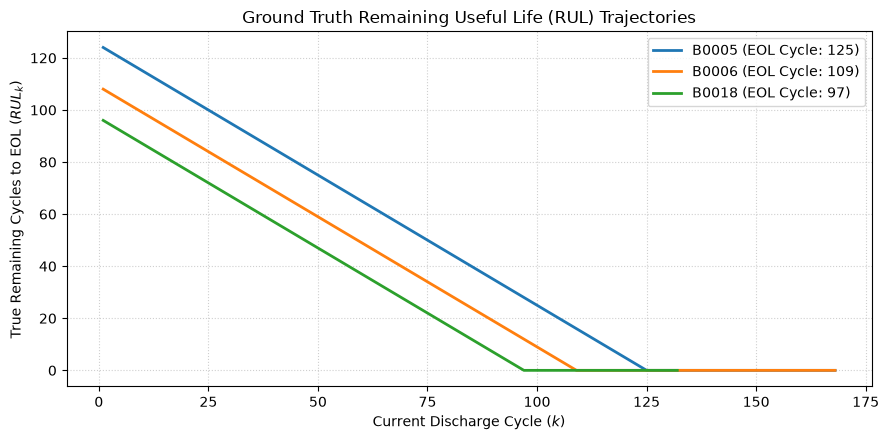

In [3]:
import matplotlib.pyplot as plt

eol_threshold_ah = 1.40  # 70% of 2.0 Ah

rul_data = []
print("--- End-of-Life (EOL) Cycle Analysis (Threshold: 1.40 Ah) ---")
plt.figure(figsize=(9, 4.5), dpi=100)

for bid in ["B0005", "B0006", "B0018"]:
    cell_dis = meta_df[(meta_df["battery_id"] == bid) & (meta_df["type"] == "discharge")].copy()
    cell_dis["Capacity"] = pd.to_numeric(cell_dis["Capacity"], errors="coerce")
    cell_dis = cell_dis.dropna(subset=["Capacity"]).reset_index(drop=True)
    cell_dis["cycle"] = np.arange(1, len(cell_dis) + 1)
    
    # Find first cycle where capacity drops below 1.40 Ah
    below_eol = cell_dis[cell_dis["Capacity"] <= eol_threshold_ah]
    if not below_eol.empty:
        k_eol = below_eol["cycle"].iloc[0]
        print(f"Battery {bid}: Reaches EOL at Cycle {k_eol} (Total recorded cycles: {len(cell_dis)})")
        cell_dis["RUL_true"] = np.maximum(0, k_eol - cell_dis["cycle"])
        plt.plot(cell_dis["cycle"], cell_dis["RUL_true"], lw=2, label=f"{bid} (EOL Cycle: {k_eol})")
    else:
        print(f"Battery {bid}: Did not cross EOL during test horizon.")

plt.title("Ground Truth Remaining Useful Life (RUL) Trajectories")
plt.xlabel("Current Discharge Cycle ($k$)")
plt.ylabel("True Remaining Cycles to EOL ($RUL_k$)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 4: Impedance Growth (Re & Rct) vs Capacity Degradation
* **Analytical Question**: Does internal charge transfer resistance ($R_{ct}$) increase concurrently as discharge capacity fades?
* **Why It Matters to HeatSense**: Validates using impedance growth as an independent degradation feature for Model B and confirms whether an impedance SoH proxy ($SoH_R$) correlates with capacity SoH.
* **What the Code Does**: Filters clean EIS impedance measurements ($0 < R_e < 1.0\Omega$, $0 < R_{ct} < 10.0\Omega$), aligns them with cycle indices for `B0005`, and plots dual-axis impedance growth alongside capacity fade.
* **Output to Inspect**: Dual-axis plot showing capacity drop vs $R_{ct}$ exponential rise.
* **Decision**: Confirms $R_{ct}$ as a high-value precursor feature for Model B.

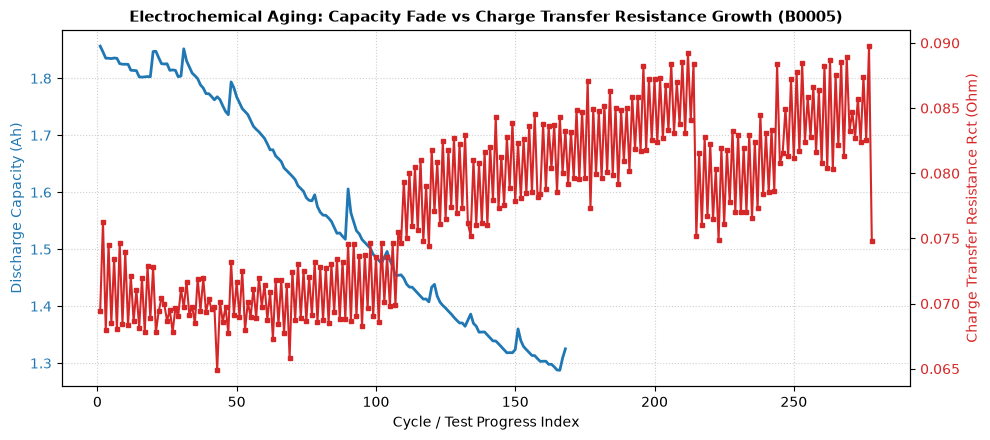

B0005 Rct Evolution: 0.0695 Ohm -> 0.0748 Ohm (Growth: +7.7%)


In [4]:
# Filter B0005 clean impedance tests
b5_imp = meta_df[(meta_df["battery_id"] == "B0005") & (meta_df["type"] == "impedance")].copy()
b5_imp["Re"] = pd.to_numeric(b5_imp["Re"], errors="coerce")
b5_imp["Rct"] = pd.to_numeric(b5_imp["Rct"], errors="coerce")

# Filter physical bounds (reject negative and extreme outlier values)
b5_imp_clean = b5_imp[(b5_imp["Re"] > 0) & (b5_imp["Re"] < 0.5) & (b5_imp["Rct"] > 0) & (b5_imp["Rct"] < 1.0)].copy()
b5_imp_clean["imp_index"] = np.arange(1, len(b5_imp_clean) + 1)

# Get B0005 discharge capacity
b5_dis = meta_df[(meta_df["battery_id"] == "B0005") & (meta_df["type"] == "discharge")].copy()
b5_dis["Capacity"] = pd.to_numeric(b5_dis["Capacity"], errors="coerce")
b5_dis["dis_index"] = np.arange(1, len(b5_dis) + 1)

fig, ax1 = plt.subplots(figsize=(10, 4.5), dpi=100)

color = "tab:blue"
ax1.set_xlabel("Cycle / Test Progress Index")
ax1.set_ylabel("Discharge Capacity (Ah)", color=color)
ax1.plot(b5_dis["dis_index"], b5_dis["Capacity"], color=color, lw=2, label="Capacity (Ah)")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = ax1.twinx()
color = "tab:red"
ax2.set_ylabel("Charge Transfer Resistance Rct (Ohm)", color=color)
ax2.plot(b5_imp_clean["imp_index"], b5_imp_clean["Rct"], color=color, marker="s", markersize=3, lw=1.5, label="Impedance Rct")
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Electrochemical Aging: Capacity Fade vs Charge Transfer Resistance Growth (B0005)", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

rct_init = b5_imp_clean['Rct'].iloc[0]
rct_final = b5_imp_clean['Rct'].iloc[-1]
print(f"B0005 Rct Evolution: {rct_init:.4f} Ohm -> {rct_final:.4f} Ohm (Growth: +{((rct_final-rct_init)/rct_init)*100:.1f}%)")

### Cell 5: Synthesis & Target Feasibility Contract Matrix
* **Analytical Question**: What is the authoritative specification for all targets across Phase 1 modeling?
* **Why It Matters to HeatSense**: Formulates the formal API and ML targets specification for `heatsense.ml.targets`.
* **What the Code Does**: Summarizes verified feasibility status, units, formulas, and target leakage rules.
* **Output to Inspect**: Target feasibility contract table.
* **Decision**: Approves advancing to Notebook 04 (2RC ECM Parameter Identification).

In [5]:
contracts = [
    {"Target": "State of Charge (SoC)", "Type": "Estimated State", "Formula": "1.0 - integral(I dt) / Qn", "Unit": "Fraction [0, 1]", "Feasibility": "FEASIBLE (via EKF)", "Leakage Rule": "Never use future current"},
    {"Target": "Capacity SoH (SoH_Q)", "Type": "Supervised ML", "Formula": "Q_meas / 2.0 * 100%", "Unit": "Percentage (%)", "Feasibility": "FEASIBLE (Cycle-level)", "Leakage Rule": "Cycle-wise aggregation only"},
    {"Target": "Remaining Useful Life (RUL)", "Type": "Prognostic ML", "Formula": "max(0, k_EOL - k)", "Unit": "Cycles", "Feasibility": "FEASIBLE (B0005, B0006, B0018)", "Leakage Rule": "Strict cell-wise split"},
    {"Target": "Resistance SoH Proxy (SoH_R)", "Type": "Derived Proxy", "Formula": "Rct_init / Rct_current", "Unit": "Ratio [0, 1]", "Feasibility": "FEASIBLE (Proxy)", "Leakage Rule": "Exclude Rct from input features"},
    {"Target": "Core Temperature (T_core)", "Type": "Model Estimate", "Formula": "Two-Node Lumped Model", "Unit": "deg C", "Feasibility": "ESTIMATED (No ground truth)", "Leakage Rule": "Explicitly label as Estimate"},
]

target_matrix_df = pd.DataFrame(contracts)
print("="*75)
print("HEATSENSE PHASE 1 TARGET FEASIBILITY SPECIFICATION")
print("="*75)
display(target_matrix_df)

HEATSENSE PHASE 1 TARGET FEASIBILITY SPECIFICATION


,Target,Type,Formula,Unit,Feasibility,Leakage Rule
0,State of Charge (SoC),Estimated State,1.0 - integral(I dt) / Qn,"Fraction [0, 1]",FEASIBLE (via EKF),Never use future current
1,Capacity SoH (SoH_Q),Supervised ML,Q_meas / 2.0 * 100%,Percentage (%),FEASIBLE (Cycle-level),Cycle-wise aggregation only
2,Remaining Useful Life (RUL),Prognostic ML,"max(0, k_EOL - k)",Cycles,"FEASIBLE (B0005, B0006, B0018)",Strict cell-wise split
3,Resistance SoH Proxy (SoH_R),Derived Proxy,Rct_init / Rct_current,"Ratio [0, 1]",FEASIBLE (Proxy),Exclude Rct from input features
4,Core Temperature (T_core),Model Estimate,Two-Node Lumped Model,deg C,ESTIMATED (No ground truth),Explicitly label as Estimate
